In [1]:
print("hello")

hello


In [2]:
import pandas as pd

movies = pd.read_csv("../data/raw/movies.csv")
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [3]:
movies.shape

(9742, 3)

In [4]:
ratings = pd.read_csv("../data/raw/ratings.csv")
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [5]:
ratings.shape

(100836, 4)

In [6]:
tags = pd.read_csv("../data/raw/tags.csv")
tags.head()

,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


In [7]:
tags.shape

(3683, 4)

In [8]:
links = pd.read_csv("../data/raw/links.csv")
links.head()

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


In [9]:
links.shape

(9742, 3)

In [10]:
movies.isnull().sum()

movieId    0
title      0
genres     0
dtype: int64

In [11]:
ratings.isnull().sum()

userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

In [12]:
tags.isnull().sum()

userId       0
movieId      0
tag          0
timestamp    0
dtype: int64

In [13]:
links.isnull().sum()

movieId    0
imdbId     0
tmdbId     8
dtype: int64

In [14]:
ratings.duplicated(subset=["userId","movieId"]).sum()

np.int64(0)

In [15]:
movies.duplicated().sum()

np.int64(0)

In [16]:
tags.duplicated().sum()

np.int64(0)

In [17]:
links.duplicated().sum()

np.int64(0)

In [18]:
movies["year"] = movies["title"].str.extract(r"\((\d{4})\)$")
movies.head()

,movieId,title,genres,year
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995
2,3,Grumpier Old Men (1995),Comedy|Romance,1995
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995
4,5,Father of the Bride Part II (1995),Comedy,1995


In [19]:
movies["year"] = movies["year"].astype('Int64')
movies["year"].dtype

Int64Dtype()

In [20]:
movies["year"].isnull().sum()

np.int64(24)

In [21]:
movies[movies["year"].isnull()]

,movieId,title,genres,year
5609,27008,From Dusk Till Dawn 2: Texas Blood Money (1999),Comedy|Crime|Horror,<NA>
6059,40697,Babylon 5,Sci-Fi,<NA>
6706,58404,Justice League: The New Frontier (2008),Action|Adventure|Animation|Fantasy|Sci-Fi,<NA>
6718,58842,Assembly (Ji jie hao) (2007),Action|Drama|War,<NA>
7878,94494,96 Minutes (2011),Drama|Thriller,<NA>
7896,95004,Superman/Doomsday (2007),Action|Animation,<NA>
7910,95193,Pocahontas II: Journey to a New World (1998),Adventure|Animation|Children,<NA>
7978,96608,Runaway Brain (1995),Animation|Comedy|Sci-Fi,<NA>
8148,102084,Justice League: Doom (2012),Action|Animation|Fantasy,<NA>
8228,104017,3 dev adam (Three Giant Men) (1973),Action|Adventure|Sci-Fi,<NA>


In [22]:
title = movies.loc[5609, "title"]
print(repr(title))

'From Dusk Till Dawn 2: Texas Blood Money (1999) '


In [23]:
type(movies)

pandas.DataFrame

In [24]:
extra_space = movies["title"] != movies["title"].str.strip()
extra_space.sum()

np.int64(11)

In [25]:
movies["title"] = movies["title"].str.strip()

In [26]:
movies["year"] = movies["title"].str.extract(r"\((\d{4})\)$")
movies["year"] = movies["year"].astype("Int64")

In [27]:
movies["year"].isnull().sum()

np.int64(13)

In [28]:
movies.loc[6059, "year"] =1994
movies.loc[9031, "year"] = 2018
movies.loc[9091, "year"] = 2015
movies.loc[9138, "year"] = 1987
movies.loc[9179, "year"] = 2016
movies.loc[9259, "year"] = 2016
movies.loc[9367, "year"] = 2016
movies.loc[9448, "year"] = 2016
movies.loc[9514, "year"] = 1980
movies.loc[9515, "year"] = 2017
movies.loc[9518, "year"] = 2006
movies.loc[9525, "year"] = 2017
movies.loc[9611, "year"] = 2011 

In [29]:
movies["genres"].str.split("|").head()

0    [Adventure, Animation, Children, Comedy, Fantasy]
1                       [Adventure, Children, Fantasy]
2                                    [Comedy, Romance]
3                             [Comedy, Drama, Romance]
4                                             [Comedy]
Name: genres, dtype: object

In [30]:
movies["genres_list"] = movies["genres"].str.split("|")
movies.head()

,movieId,title,genres,year,genres_list
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,"[Adventure, Animation, Children, Comedy, Fantasy]"
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,"[Adventure, Children, Fantasy]"
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,"[Comedy, Romance]"
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995,"[Comedy, Drama, Romance]"
4,5,Father of the Bride Part II (1995),Comedy,1995,[Comedy]


In [31]:
rating_counts = ratings.groupby("movieId").size()
rating_counts.head()

movieId
1    215
2    110
3     52
4      7
5     49
dtype: int64

In [32]:
rating_counts = rating_counts.sort_values(ascending=False)
rating_counts.head(20)

movieId
356     329
318     317
296     307
593     279
2571    278
260     251
480     238
110     237
589     224
527     220
2959    218
1       215
1196    211
2858    204
50      204
47      203
780     202
150     201
1198    200
4993    198
dtype: int64

In [33]:
rating_counts_df = rating_counts.reset_index(name="rating_counts")
rating_counts_df.head()

,movieId,rating_counts
0,356,329
1,318,317
2,296,307
3,593,279
4,2571,278


In [34]:
top_movies = rating_counts_df.merge(movies,on="movieId")
top_movies = top_movies.sort_values("rating_counts",ascending=False)
top_movies[["title","rating_counts"]].head(10)

,title,rating_counts
0,Forrest Gump (1994),329
1,"Shawshank Redemption, The (1994)",317
2,Pulp Fiction (1994),307
3,"Silence of the Lambs, The (1991)",279
4,"Matrix, The (1999)",278
5,Star Wars: Episode IV - A New Hope (1977),251
6,Jurassic Park (1993),238
7,Braveheart (1995),237
8,Terminator 2: Judgment Day (1991),224
9,Schindler's List (1993),220


In [35]:
avg_rating = ratings.groupby("movieId")["rating"].mean()
avg_rating.head()

movieId
1    3.920930
2    3.431818
3    3.259615
4    2.357143
5    3.071429
Name: rating, dtype: float64

In [36]:
avg_rating_df = avg_rating.reset_index(name="avg_rating") 
avg_rating_df.head()

,movieId,avg_rating
0,1,3.920930
1,2,3.431818
2,3,3.259615
3,4,2.357143
4,5,3.071429


In [37]:
top_movies = avg_rating_df.merge(top_movies,on="movieId")
top_movies.head()

,movieId,avg_rating,rating_counts,title,genres,year,genres_list
0,1,3.920930,215,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,"[Adventure, Animation, Children, Comedy, Fantasy]"
1,2,3.431818,110,Jumanji (1995),Adventure|Children|Fantasy,1995,"[Adventure, Children, Fantasy]"
2,3,3.259615,52,Grumpier Old Men (1995),Comedy|Romance,1995,"[Comedy, Romance]"
3,4,2.357143,7,Waiting to Exhale (1995),Comedy|Drama|Romance,1995,"[Comedy, Drama, Romance]"
4,5,3.071429,49,Father of the Bride Part II (1995),Comedy,1995,[Comedy]


In [38]:
top_movies.sort_values("avg_rating",ascending=False).head(10)

,movieId,avg_rating,rating_counts,title,genres,year,genres_list
9693,187717,5.0,1,Won't You Be My Neighbor? (2018),Documentary,2018,[Documentary]
4667,6983,5.0,1,Jane Eyre (1944),Drama|Romance,1944,"[Drama, Romance]"
3802,5328,5.0,1,Rain (2001),Drama|Romance,2001,"[Drama, Romance]"
7927,95843,5.0,1,Goodbye Charlie (1964),Comedy|Fantasy|Romance,1964,"[Comedy, Fantasy, Romance]"
2934,3941,5.0,1,Sorority House Massacre (1986),Horror,1986,[Horror]
2933,3940,5.0,1,Slumber Party Massacre III (1990),Horror,1990,[Horror]
2932,3939,5.0,1,Slumber Party Massacre II (1987),Horror,1987,[Horror]
5015,7815,5.0,1,True Stories (1986),Comedy|Musical,1986,"[Comedy, Musical]"
9349,162414,5.0,1,Moonlight,Drama,2016,[Drama]
9347,162344,5.0,1,Tom Segura: Mostly Stories (2016),Comedy,2016,[Comedy]


In [39]:
c = ratings["rating"].mean()
c

np.float64(3.501556983616962)

In [40]:
m = top_movies["rating_counts"].quantile(0.90)
m

np.float64(27.0)

In [41]:
def weighted_rating(row, m=m, c=c):
    v = row["rating_counts"]
    R = row["avg_rating"]
    return (v / (v + m) * R) + (m / (v + m) * c)

top_movies["weighted_rating"] = top_movies.apply(weighted_rating, axis=1)

In [42]:
top_movies.head()

,movieId,avg_rating,rating_counts,title,genres,year,genres_list,weighted_rating
0,1,3.920930,215,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,"[Adventure, Animation, Children, Comedy, Fantasy]",3.874141
1,2,3.431818,110,Jumanji (1995),Adventure|Children|Fantasy,1995,"[Adventure, Children, Fantasy]",3.445562
2,3,3.259615,52,Grumpier Old Men (1995),Comedy|Romance,1995,"[Comedy, Romance]",3.342304
3,4,2.357143,7,Waiting to Exhale (1995),Comedy|Drama|Romance,1995,"[Comedy, Drama, Romance]",3.265942
4,5,3.071429,49,Father of the Bride Part II (1995),Comedy,1995,[Comedy],3.224237


In [43]:
top_movies.sort_values("weighted_rating", ascending=False)[["title", "avg_rating", "rating_counts", "weighted_rating"]].head(50)

,title,avg_rating,rating_counts,weighted_rating
277,"Shawshank Redemption, The (1994)",4.429022,317,4.356227
659,"Godfather, The (1972)",4.289062,192,4.191973
2224,Fight Club (1999),4.272936,218,4.187927
224,Star Wars: Episode IV - A New Hope (1977),4.231076,251,4.160223
46,"Usual Suspects, The (1995)",4.237745,204,4.151697
461,Schindler's List (1993),4.225000,220,4.145919
257,Pulp Fiction (1994),4.197068,307,4.140844
897,Star Wars: Episode V - The Empire Strikes Back...,4.215640,211,4.134630
1938,"Matrix, The (1999)",4.192446,278,4.131285
921,"Godfather: Part II, The (1974)",4.259690,129,4.128475


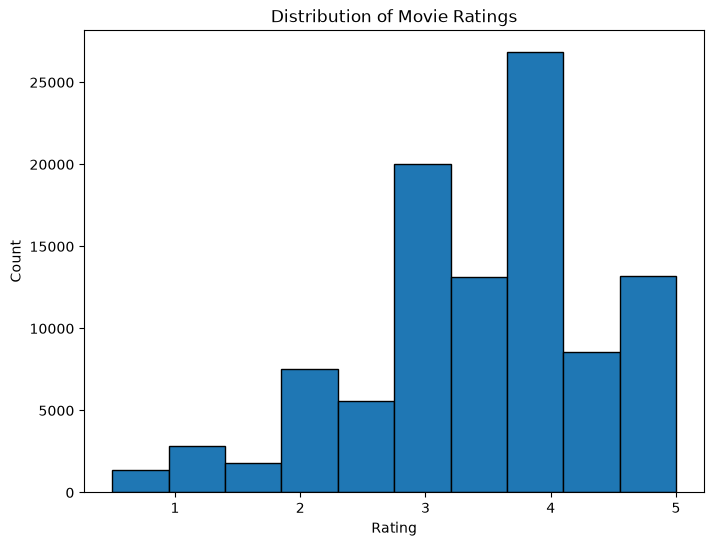

In [44]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.hist(ratings["rating"], bins=10 , edgecolor="black")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.title("Distribution of Movie Ratings")
plt.show()

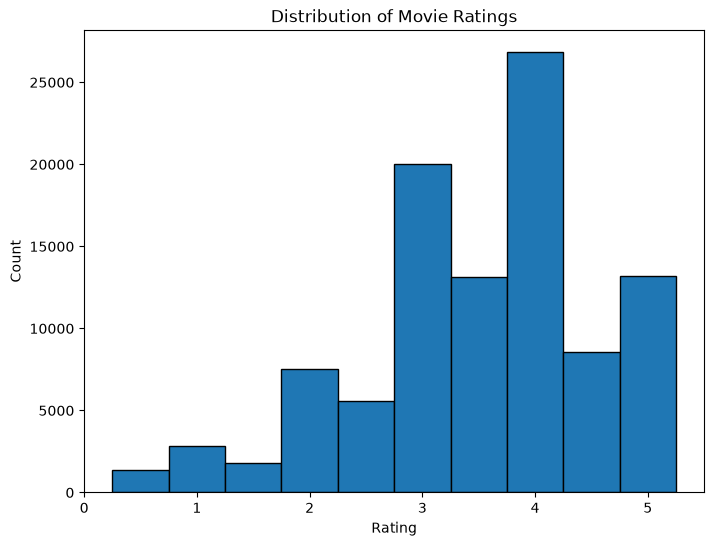

In [45]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))
plt.hist(ratings["rating"], bins=np.arange(0.25, 5.5, 0.5) , edgecolor="black")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.title("Distribution of Movie Ratings")
plt.show()

In [46]:
user_activaties = ratings.groupby("userId").size()
user_activaties.describe()

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64

In [47]:
user_activaties

userId
1       232
2        29
3        39
4       216
5        44
       ... 
606    1115
607     187
608     831
609      37
610    1302
Length: 610, dtype: int64

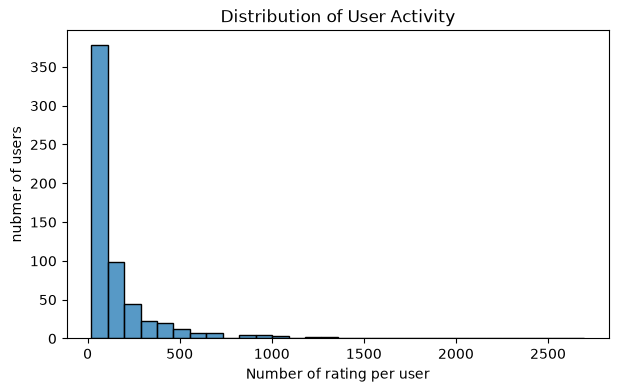

In [48]:
import seaborn as sns

plt.figure(figsize=(7,4))
sns.histplot(user_activaties,bins = 30)
plt.xlabel("Number of rating per user")
plt.ylabel("nubmer of users")
plt.title("Distribution of User Activity")
plt.show()

In [49]:
exploded = movies.explode("genres_list")
exploded.head(10)

,movieId,title,genres,year,genres_list
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,Adventure
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,Animation
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,Children
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,Comedy
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,Adventure
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,Children
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,Comedy
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,Romance


In [50]:
genre_counts = exploded["genres_list"].value_counts()
genre_counts

genres_list
Drama                 4361
Comedy                3756
Thriller              1894
Action                1828
Romance               1596
Adventure             1263
Crime                 1199
Sci-Fi                 980
Horror                 978
Fantasy                779
Children               664
Animation              611
Mystery                573
Documentary            440
War                    382
Musical                334
Western                167
IMAX                   158
Film-Noir               87
(no genres listed)      34
Name: count, dtype: int64

In [51]:
genre_counts = genre_counts.drop("(no genres listed)")
genre_counts

genres_list
Drama          4361
Comedy         3756
Thriller       1894
Action         1828
Romance        1596
Adventure      1263
Crime          1199
Sci-Fi          980
Horror          978
Fantasy         779
Children        664
Animation       611
Mystery         573
Documentary     440
War             382
Musical         334
Western         167
IMAX            158
Film-Noir        87
Name: count, dtype: int64

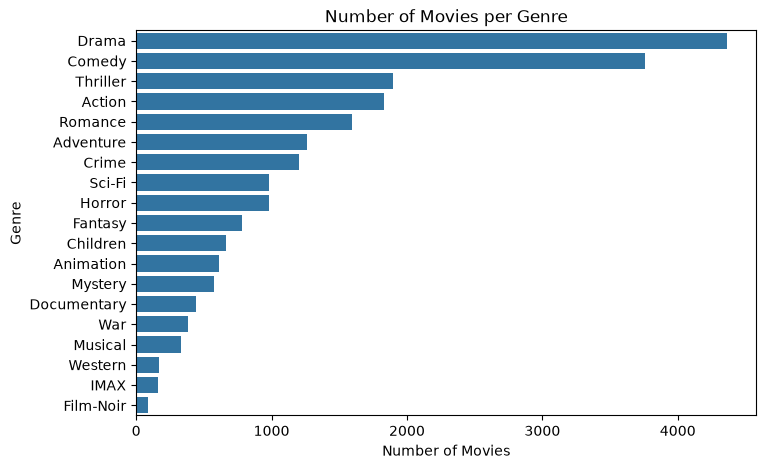

In [52]:
plt.figure(figsize=(8,5))
sns.barplot(x=genre_counts.values, y=genre_counts.index)
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.title("Number of Movies per Genre")
plt.show()

In [53]:
top_exploded = movies.merge(ratings,on="movieId")

top_exploded = top_exploded.explode("genres_list")
potato = top_exploded.groupby("genres_list")["rating"].mean().sort_values(ascending=False)
potato

genres_list
Film-Noir             3.920115
War                   3.808294
Documentary           3.797785
Crime                 3.658294
Drama                 3.656184
Mystery               3.632460
Animation             3.629937
IMAX                  3.618335
Western               3.583938
Musical               3.563678
Adventure             3.508609
Romance               3.506511
Thriller              3.493706
Fantasy               3.491001
(no genres listed)    3.489362
Sci-Fi                3.455721
Action                3.447984
Children              3.412956
Comedy                3.384721
Horror                3.258195
Name: rating, dtype: float64

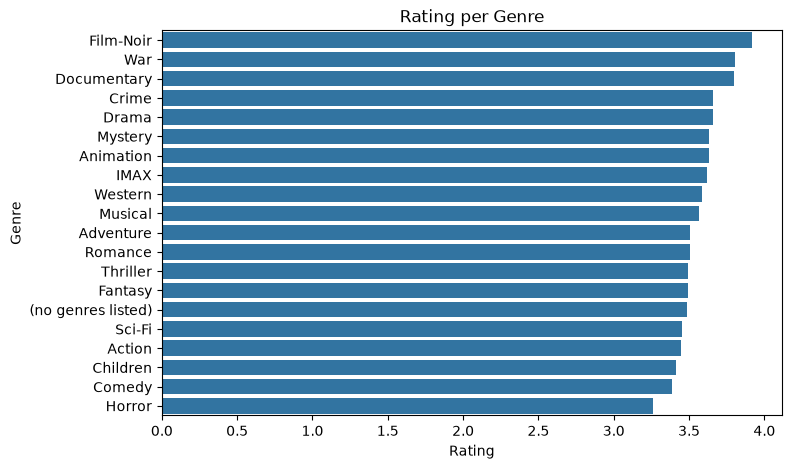

In [54]:
plt.figure(figsize=(8,5))
sns.barplot(x=potato.values, y=potato.index)
plt.xlabel("Rating")
plt.ylabel("Genre")
plt.title("Rating per Genre")
plt.show()

In [55]:
genre_avg_rating = top_exploded.groupby("genres_list")["rating"].mean().sort_values(ascending=False)
genre_avg_rating

genres_list
Film-Noir             3.920115
War                   3.808294
Documentary           3.797785
Crime                 3.658294
Drama                 3.656184
Mystery               3.632460
Animation             3.629937
IMAX                  3.618335
Western               3.583938
Musical               3.563678
Adventure             3.508609
Romance               3.506511
Thriller              3.493706
Fantasy               3.491001
(no genres listed)    3.489362
Sci-Fi                3.455721
Action                3.447984
Children              3.412956
Comedy                3.384721
Horror                3.258195
Name: rating, dtype: float64

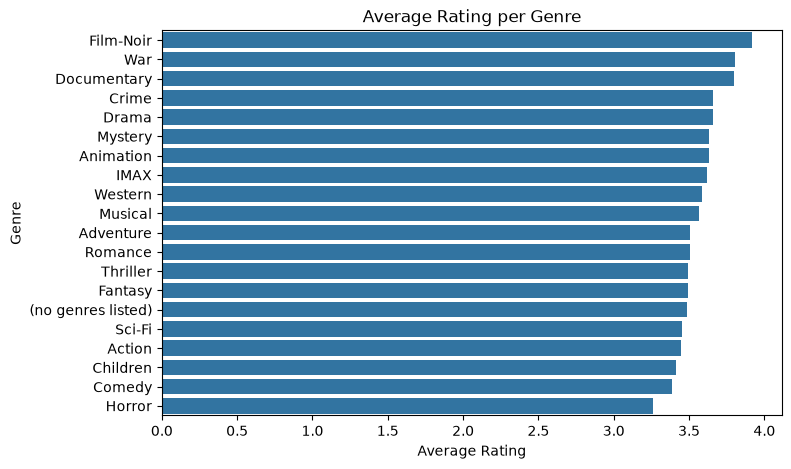

In [56]:
plt.figure(figsize=(8, 5))
sns.barplot(x=genre_avg_rating.values, y=genre_avg_rating.index)
plt.xlabel("Average Rating")
plt.ylabel("Genre")
plt.title("Average Rating per Genre")
plt.show()

In [57]:
movies["genres_str"]=movies["genres"].str.replace("|"," ",regex=False)
movies

,movieId,title,genres,year,genres_list,genres_str
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,"[Adventure, Animation, Children, Comedy, Fantasy]",Adventure Animation Children Comedy Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,"[Adventure, Children, Fantasy]",Adventure Children Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,"[Comedy, Romance]",Comedy Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995,"[Comedy, Drama, Romance]",Comedy Drama Romance
4,5,Father of the Bride Part II (1995),Comedy,1995,[Comedy],Comedy
...,...,...,...,...,...,...
9737,193581,Black Butler: Book of the Atlantic (2017),Action|Animation|Comedy|Fantasy,2017,"[Action, Animation, Comedy, Fantasy]",Action Animation Comedy Fantasy
9738,193583,No Game No Life: Zero (2017),Animation|Comedy|Fantasy,2017,"[Animation, Comedy, Fantasy]",Animation Comedy Fantasy
9739,193585,Flint (2017),Drama,2017,[Drama],Drama
9740,193587,Bungo Stray Dogs: Dead Apple (2018),Action|Animation,2018,"[Action, Animation]",Action Animation


In [58]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
tfidf_matrix =tfidf.fit_transform(movies["genres_str"])
tfidf_matrix.shape

(9742, 24)

In [59]:
tfidf.get_feature_names_out()

array(['action', 'adventure', 'animation', 'children', 'comedy', 'crime',
       'documentary', 'drama', 'fantasy', 'fi', 'film', 'genres',
       'horror', 'imax', 'listed', 'musical', 'mystery', 'no', 'noir',
       'romance', 'sci', 'thriller', 'war', 'western'], dtype=object)

In [60]:
movies_content = movies[movies["genres"] != "(no genres listed)"].copy()
movies_content.shape

(9708, 6)

In [61]:
movies_content["genres_str"] = movies["genres"].str.replace("|"," ",regex=False)
movies_content["genres_str"] = movies["genres_str"].str.replace("-","",regex=False)
movies_content.head(10)

,movieId,title,genres,year,genres_list,genres_str
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,"[Adventure, Animation, Children, Comedy, Fantasy]",Adventure Animation Children Comedy Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,"[Adventure, Children, Fantasy]",Adventure Children Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,"[Comedy, Romance]",Comedy Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995,"[Comedy, Drama, Romance]",Comedy Drama Romance
4,5,Father of the Bride Part II (1995),Comedy,1995,[Comedy],Comedy
5,6,Heat (1995),Action|Crime|Thriller,1995,"[Action, Crime, Thriller]",Action Crime Thriller
6,7,Sabrina (1995),Comedy|Romance,1995,"[Comedy, Romance]",Comedy Romance
7,8,Tom and Huck (1995),Adventure|Children,1995,"[Adventure, Children]",Adventure Children
8,9,Sudden Death (1995),Action,1995,[Action],Action
9,10,GoldenEye (1995),Action|Adventure|Thriller,1995,"[Action, Adventure, Thriller]",Action Adventure Thriller


In [62]:
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(movies_content["genres_str"])
tfidf_matrix.shape

(9708, 19)

In [63]:
tfidf.get_feature_names_out()

array(['action', 'adventure', 'animation', 'children', 'comedy', 'crime',
       'documentary', 'drama', 'fantasy', 'filmnoir', 'horror', 'imax',
       'musical', 'mystery', 'romance', 'scifi', 'thriller', 'war',
       'western'], dtype=object)

In [64]:
from sklearn.metrics.pairwise import cosine_similarity

cosine_sim = cosine_similarity(tfidf_matrix,tfidf_matrix)
cosine_sim.shape

(9708, 9708)

In [65]:
movies_content = movies_content.reset_index(drop=0)
indices = pd.Series(movies_content.index, index=movies_content["title"])
indices.head()


title
Toy Story (1995)                      0
Jumanji (1995)                        1
Grumpier Old Men (1995)               2
Waiting to Exhale (1995)              3
Father of the Bride Part II (1995)    4
dtype: int64

In [66]:
def get_recommendations(title, cosine_sim = cosine_sim):
    idx = indices[title]
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key = lambda x: x[1], reverse=True)
    sim_scores = [s for s in sim_scores if s[0] != idx] 
    sim_scores = sim_scores[:10]
    movies_indices =[i[0] for i in sim_scores]
    return movies_content["title"].iloc[movies_indices]
get_recommendations("Toy Story (1995)")

1706                                          Antz (1998)
2355                                   Toy Story 2 (1999)
2809       Adventures of Rocky and Bullwinkle, The (2000)
3000                     Emperor's New Groove, The (2000)
3568                                Monsters, Inc. (2001)
6194                                     Wild, The (2006)
6486                               Shrek the Third (2007)
6948                       Tale of Despereaux, The (2008)
7760    Asterix and the Vikings (Astérix et les Viking...
8219                                         Turbo (2013)
Name: title, dtype: str

In [67]:
user_item_matrix = ratings.pivot_table(index="userId", columns="movieId", values="rating")
user_item_matrix.shape

(610, 9724)

In [68]:
user_item_matrix.head()

movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [69]:
total_cells = user_item_matrix.shape[0] * user_item_matrix.shape[1]
filled_cells = ratings.shape[0]
sparsity = 1 - (filled_cells / total_cells)
sparsity

0.9830003169443864

In [70]:
import numpy as np
from scipy.sparse.linalg import svds

user_ratings_mean = user_item_matrix.mean(axis=1)
R_demeaned = user_item_matrix.sub(user_ratings_mean, axis=0).fillna(0)

U, sigma, Vt = svds(R_demeaned.values, k=50)
sigma = np.diag(sigma)

In [71]:
all_user_predicted_ratings = np.dot(np.dot(U, sigma),Vt) + user_ratings_mean.values.reshape(-1,1)
preds_df = pd.DataFrame(all_user_predicted_ratings, columns=user_item_matrix.columns, index=user_item_matrix.index)
preds_df.head()

movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.306161,4.296397,4.405951,4.370563,4.342908,4.163808,4.204276,4.341084,4.379745,4.277329,...,4.366767,4.367710,4.365823,4.365823,4.366767,4.365823,4.366767,4.366767,4.366767,4.367243
2,3.945985,3.932260,3.936752,3.953256,3.956456,3.932349,3.931181,3.950689,3.952856,3.980600,...,3.948198,3.948010,3.948387,3.948387,3.948198,3.948387,3.948198,3.948198,3.948198,3.947933
3,2.425206,2.473104,2.404444,2.442252,2.462691,2.432406,2.441692,2.451316,2.427452,2.472199,...,2.435901,2.435910,2.435892,2.435892,2.435901,2.435892,2.435901,2.435901,2.435901,2.435954
4,3.591391,3.542791,3.567743,3.501296,3.618028,3.607064,3.677209,3.523268,3.549899,3.693275,...,3.556530,3.558903,3.554156,3.554156,3.556530,3.554156,3.556530,3.556530,3.556530,3.550811
5,3.826923,3.623178,3.619512,3.618412,3.607475,3.735154,3.644817,3.634681,3.622817,3.590988,...,3.636455,3.636679,3.636232,3.636232,3.636455,3.636232,3.636455,3.636455,3.636455,3.636856


In [72]:
def recommend_movies_svd(user_id, n_recommendations=10):
    user_row = preds_df.loc[user_id].sort_values(ascending=False)

    already_rated = user_item_matrix.loc[user_id].dropna().index
    recommendations = user_row.drop(already_rated).head(n_recommendations)
    return movies_content[movies_content["movieId"].isin(recommendations.index)][["movieId", "title"]]

recommend_movies_svd(266)

,movieId,title
43,47,Seven (a.k.a. Se7en) (1995)
254,293,Léon: The Professional (a.k.a. The Professiona...
277,318,"Shawshank Redemption, The (1994)"
659,858,"Godfather, The (1972)"
922,1221,"Godfather: Part II, The (1974)"
1402,1921,Pi (1998)
1917,2542,"Lock, Stock & Two Smoking Barrels (1998)"
2145,2858,American Beauty (1999)
2983,3996,"Crouching Tiger, Hidden Dragon (Wo hu cang lon..."
4529,6711,Lost in Translation (2003)


In [73]:
from surprise import Dataset, Reader

reader = Reader(rating_scale=(0.5,5.0))
data = Dataset.load_from_df(ratings[["userId","movieId","rating"]], reader)

In [74]:
from surprise import SVD
from surprise.model_selection import cross_validate

algorithm = SVD()
res = cross_validate(algorithm, data, measures=["RMSE","MAE"], cv=5, verbose=True)

Evaluating RMSE, MAE of algorithm SVD on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    0.8702  0.8758  0.8791  0.8655  0.8774  0.8736  0.0050  
MAE (testset)     0.6708  0.6744  0.6746  0.6637  0.6747  0.6717  0.0042  
Fit time          1.03    0.93    1.09    0.89    0.95    0.98    0.07    
Test time         0.14    0.09    0.08    0.08    0.08    0.09    0.02    


In [75]:
trainset = data.build_full_trainset()
algorithm.fit(trainset)

In [76]:
prediction = algorithm.predict(uid=1, iid=1)
prediction

Prediction(uid=1, iid=1, r_ui=None, est=np.float64(4.664171837607252), details={'was_impossible': False})

In [77]:
def get_surprise_svd(user_id, recommendations_n=10):
    movie_ids = movies_content["movieId"]
    rated_movies1 = ratings[ratings["userId"]==user_id]["movieId"].values
    unrated_movies = [m for m in movie_ids if m not in rated_movies1]
    predictions = [algorithm.predict(uid=user_id, iid=movie_id) for movie_id in unrated_movies]
    predictions.sort(key=lambda x: x.est, reverse=True)
    top_predictions = predictions[:recommendations_n]

    top_movie_ids = [pred.iid for pred in top_predictions]
    return movies_content[movies_content["movieId"].isin(top_movie_ids)][["movieId", "title"]]
get_surprise_svd(1)

,movieId,title
147,175,Kids (1995)
277,318,"Shawshank Redemption, The (1994)"
681,899,Singin' in the Rain (1952)
686,904,Rear Window (1954)
690,908,North by Northwest (1959)
694,912,Casablanca (1942)
704,922,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950)
731,951,His Girl Friday (1940)
841,1104,"Streetcar Named Desire, A (1951)"
868,1148,Wallace & Gromit: The Wrong Trousers (1993)


In [78]:
from surprise.model_selection import train_test_split as surprise_train_test_split

trainset, testset =  surprise_train_test_split(data, test_size=0.2, random_state = 67)
algo_eval = SVD()
algo_eval.fit(trainset)
predictions = algo_eval.test(testset)

In [79]:
from collections import defaultdict

def precision_recall_at_k(predictions, k = 10 , threshold=4.0):
    user_predictions = defaultdict(list)
    for pred in predictions:
        user_predictions[pred.uid].append((pred.est, pred.r_ui))
    precisions = {}
    recalls = {}
    for uid, user_ratings in user_predictions.items():
        user_ratings.sort(key=lambda x: x[0], reverse = True)
        n_relevant = sum((true_r >= threshold) for (_, true_r) in user_ratings)
        n_rec_k = min(k, len(user_ratings))
        n_relevant_rec_k = sum((true_r >= threshold) for (_, true_r) in user_ratings[:k])
        precisions[uid] = n_relevant_rec_k / n_rec_k if n_rec_k != 0 else 0
        recalls[uid] = n_relevant_rec_k / n_relevant if n_relevant != 0 else 0 
    return precisions, recalls

In [80]:
precisions, recalls = precision_recall_at_k(predictions, k=10, threshold=4.0)

avg_precision = sum(precisions.values()) / len(precisions)
avg_recall = sum(recalls.values()) / len(recalls)

print(f"Precision@10: {avg_precision:.3f}")
print(f"Recall@10: {avg_recall:.3f}")

Precision@10: 0.642
Recall@10: 0.659


In [81]:
import pickle 
import os

with open("../models/algorithm_svd.pkl", "wb") as f:
    pickle.dump(algorithm, f)
with open("../models/tfidf.pkl", "wb") as f:
    pickle.dump(tfidf, f)
with open("../models/tfidf_matrix.pkl", "wb") as f:
    pickle.dump(tfidf_matrix, f)
movies_content.to_pickle("../models/movies_content.pkl")
ratings.to_pickle("../models/ratings.pkl")
print("File size:", os.path.getsize("../models/tfidf_matrix.pkl"), "bytes")

File size: 303806 bytes


In [82]:
movies_content.columns

Index(['index', 'movieId', 'title', 'genres', 'year', 'genres_list',
       'genres_str'],
      dtype='str')

In [83]:
avg_rating = ratings.groupby("movieId")["rating"].mean()
rating_counts = ratings.groupby("movieId").size()

movies_content = movies_content.merge(avg_rating.rename("avg_rating"), on="movieId", how="left")
movies_content = movies_content.merge(rating_counts.rename("rating_counts"), on="movieId", how="left")

C = ratings["rating"].mean()
m = movies_content["rating_counts"].quantile(0.90)

def weighted_rating(row, m=m, C=C):
    v = row["rating_counts"]
    R = row["avg_rating"]
    if pd.isna(v) or pd.isna(R):
        return C
    return (v / (v + m) * R) + (m / (v + m) * C)
movies_content["weighted_rating"] = movies_content.apply(weighted_rating, axis=1)

movies_content.to_pickle("../models/movies_content.pkl")

In [84]:
active_user = user_activaties[user_activaties>=30]
active_user.shape

(501,)

In [85]:
rated = user_item_matrix.notna().astype(int)
overlap_matrix = rated @ rated.T
overlap_matrix.head()

userId,1,2,3,4,5,6,7,8,9,10,...,601,602,603,604,605,606,607,608,609,610
userId,,,,,,,,,,,,,,,,,,,,,
1,232,2,7,45,13,33,26,15,5,6,...,11,27,110,12,35,84,60,136,9,69
2,2,29,0,1,1,2,3,1,0,5,...,11,1,2,0,0,5,1,6,1,18
3,7,0,39,1,1,3,0,1,0,0,...,2,2,9,0,1,8,4,9,0,7
4,45,1,1,216,12,27,22,9,1,9,...,15,23,139,9,16,96,29,74,3,53
5,13,1,1,12,44,36,9,19,0,3,...,4,31,25,19,14,23,15,30,10,14


In [86]:
overlap = overlap_matrix.to_numpy().copy()
np.fill_diagonal(overlap,0)
overlap_values = overlap[overlap>0]
pd.Series(overlap_values).describe()

count    328108.000000
mean         17.749838
std          33.077098
min           1.000000
25%           3.000000
50%           8.000000
75%          19.000000
max        1338.000000
dtype: float64

In [87]:
thresholds = [5, 10, 20]
for t in thresholds:
    count = (overlap >= t).sum() // 2
    print(f"overlap >= {t}: {count} user pairs")

overlap >= 5: 108202 user pairs
overlap >= 10: 73373 user pairs
overlap >= 20: 39527 user pairs


In [88]:
thresholds = [5, 10, 20]
for t in thresholds:
    neighbors_per_user = (overlap >= t).sum(axis=1)
    print(f"\nOverlap >= {t}")
    print(pd.Series(neighbors_per_user).describe())


Overlap >= 5
count    610.000000
mean     354.760656
std      155.134472
min        7.000000
25%      255.000000
50%      354.500000
75%      485.000000
max      609.000000
dtype: float64

Overlap >= 10
count    610.000000
mean     240.567213
std      155.187401
min        0.000000
25%      120.750000
50%      226.500000
75%      347.000000
max      608.000000
dtype: float64

Overlap >= 20
count    610.000000
mean     129.596721
std      123.650833
min        0.000000
25%       21.000000
50%      101.000000
75%      198.000000
max      562.000000
dtype: float64


In [96]:
knn_matrix = user_item_matrix.fillna(0)
knn_matrix

movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,0.0,4.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
606,2.5,0.0,0.0,0.0,0.0,0.0,2.5,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
607,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
608,2.5,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [98]:
from sklearn.neighbors import NearestNeighbors
knn_model = NearestNeighbors(metric='cosine', algorithm='brute')
knn_model.fit(knn_matrix)

,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'cosine'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


In [115]:
def find_similar_users(taste_vector, k=5):
    taste_vector_2d = taste_vector.values.reshape(1,-1)
    distances, indices2 = knn_model.kneighbors(taste_vector_2d,n_neighbors=k)
    similar_user_ids = knn_matrix.index[indices2[0]]
    return similar_user_ids, distances[0]

In [116]:
def build_taste_vector(picked_movie_ids, rating_value=5.0):
    taste_vector = pd.Series(0.0, index=knn_matrix.columns)
    taste_vector.loc[picked_movie_ids] = rating_value
    return taste_vector

In [126]:
new_user_taste = build_taste_vector(picked_movie_ids=[1, 50, 260, 921, 1729])  
similar_users, distances = find_similar_users(new_user_taste, k=5)
print(similar_users)

Index([145, 396, 228, 529, 364], dtype='int64', name='userId')


In [173]:
def find_similar_users_filtered(taste_vector, picked_movie_ids, k=5, min_overlap=4, search_k=30):
    taste_vector_2d = taste_vector.values.reshape(1, -1)
    distances, indices = knn_model.kneighbors(taste_vector_2d, n_neighbors=search_k)
    candidate_ids = knn_matrix.index[indices[0]]
    candidate_distances = distances[0]  # 
    overlap_counts = user_item_matrix.loc[candidate_ids, picked_movie_ids].notna().sum(axis=1)
    valid_candidates = overlap_counts[overlap_counts >= min_overlap].index
    final_users = []
    final_distances = []
    for uid, dist in zip(candidate_ids, candidate_distances):
        if uid in valid_candidates:
            final_users.append(uid)
            final_distances.append(dist)
        if len(final_users) == k:
            break
    return final_users, final_distances

In [175]:
filtered_users, filtered_distances = find_similar_users_filtered(
    new_user_taste, 
    picked_movie_ids=[1, 50, 260, 921, 1729], 
    k=5, 
    min_overlap=3
)
print(filtered_users)
print(filtered_distances)

[124, 96, 112, 323, 39]
[np.float64(0.8059915845084504), np.float64(0.81358907019964), np.float64(0.81397700162275), np.float64(0.8274014007769313), np.float64(0.8377785788692375)]


In [182]:
def get_coldstart_recommendations(filtered_users, distances, picked_movie_ids, top_n=10):
    svd_rec_list = [get_surprise_svd(uid, recommendations_n=10)for uid in filtered_users if uid > 0] 
    movie_scores = {}
    for user_recs, dist in zip(svd_rec_list, distances):
        weight = 1 / (dist +1e-6)
        n = len(user_recs)
        for rank, movie_id in enumerate(user_recs['movieId']):
            rank_score = (n-rank)
            movie_scores[movie_id] = movie_scores.get(movie_id,0) + (rank_score * weight)
    for movie_id in picked_movie_ids:
        movie_scores.pop(movie_id, None)
    ranked = sorted(movie_scores.items(), key=lambda x: x[1], reverse=True)
    return ranked[:top_n]

In [183]:
final_recs = get_coldstart_recommendations(
    filtered_users, 
    filtered_distances, 
    picked_movie_ids=[1, 50, 260, 921, 1729], 
    top_n=10
)
print(final_recs)

[(750, np.float64(30.367086961658245)), (318, np.float64(24.22751598668286)), (898, np.float64(21.939497776665103)), (858, np.float64(20.970287725047474)), (527, np.float64(20.715406925317538)), (1204, np.float64(15.904449562717884)), (1208, np.float64(14.626331851110068)), (246, np.float64(12.40706204027756)), (1136, np.float64(11.056809867167862)), (475, np.float64(10.742682475201201))]


In [184]:
import pickle

with open('../models/knn_model.pkl', 'wb') as f:
    pickle.dump(knn_model, f)

with open('../models/knn_matrix.pkl', 'wb') as f:
    pickle.dump(knn_matrix, f)

with open('../models/user_item_matrix.pkl', 'wb') as f:
    pickle.dump(user_item_matrix, f)